# arXiv embeddings at scale

This notebook consumes the sample and text-vector cache made by [Prepare the arXiv dataset](../data/arxiv/prepare_arxiv_dataset.ipynb). It fits one UMAP embedding and one multilevel-initialized IMSTE embedding using the selected metric, then caches both layouts for exploration in notebook 04.


## 1. Load the prepared dataset

Run `../data/arxiv/prepare_arxiv_dataset.ipynb` first if there is no cache or if you want a larger sample. Here, increasing or changing model settings does not download or re-embed text; this notebook reads the one prepared cache.

In [1]:
%load_ext autoreload
%autoreload 2

%config InlineBackend.figure_format = 'retina'

from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "pyproject.toml").exists() and (PROJECT_ROOT.parent / "pyproject.toml").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT / "notebooks" / "src"))
DATA_DIR = PROJECT_ROOT / "data" / "arxiv"
CACHE_DIR = DATA_DIR / "cache"
CACHE_DIR.mkdir(parents=True, exist_ok=True)
from arxiv_dataset import load_arxiv_dataset
papers, X, data_manifest = load_arxiv_dataset(DATA_DIR)
print(f"Loaded {len(papers):,} papers × {X.shape[1]:,} features")
print(f"Vector matrix in memory: {X.nbytes / 1024**3:.2f} GiB")
print("Dataset cache ID:", data_manifest["dataset_id"])


Loaded 1,200,000 papers × 384 features
Vector matrix in memory: 1.72 GiB
Dataset cache ID: 4270d8e4b4e3ce22990a


## 2. Prepare category labels

In [2]:
primary_category = papers["categories"].fillna("unknown").str.split().str[0]
archive = primary_category.str.split(".").str[0]
domain_names = {
    "cs": "computer science",
    "math": "mathematics",
    "eess": "engineering",
    "stat": "statistics",
    "q-bio": "biology",
    "q-fin": "finance",
    "econ": "economics",
}
domain = archive.map(domain_names).fillna("physics")
domain_order = domain.value_counts().index.tolist()
labels = pd.Categorical(domain, categories=domain_order)
display(pd.DataFrame({"primary_category": primary_category, "domain": domain}).groupby("domain", observed=True).size().sort_values(ascending=False).rename("papers"))

domain
physics             578491
computer science    313967
mathematics         227971
engineering          31327
statistics           24828
biology              13323
finance               5187
economics             4906
Name: papers, dtype: int64

## 3. Fit UMAP and multilevel IMSTE

Set the UMAP and IMSTE parameters below. The next cells show the direct estimator calls. Set `IMSTE_MST_NEIGHBOR_BACKEND` to choose the FAMST neighbor search backend independently from the optimizer device. Set `IMSTE_VERBOSE` to print timestamped stage logs and progress bars during fitting. The comparison view plots the first two IMSTE coordinates. Set `IMSTE_FORCE_REFIT = True` to refit IMSTE without refitting UMAP.


In [3]:
import umap
from arxiv_imste import prepare_arxiv_projection_cache

RANDOM_STATE = int(data_manifest["random_state"])
METRIC = "euclidean"  # or "cosine"
N_NEIGHBORS = 15
UMAP_EPOCHS = 200
UMAP_REPULSION_STRENGTH = 4
UMAP_SETTINGS = {
    "n_components": 2,
    "n_neighbors": N_NEIGHBORS,
    "min_dist": 0.1,
    "repulsion_strength": UMAP_REPULSION_STRENGTH,
    "metric": METRIC,
    "init": "recursive",
    "compatibility_layout": False,
    "nearest_neighbor_backend": "rinnd",
    "random_state": RANDOM_STATE,
    "n_epochs": UMAP_EPOCHS,
    "verbose": True,
}

# IMSTE embedding and optimizer
IMSTE_N_COMPONENTS = 2  # The comparison renderer displays the first two.
IMSTE_N_MSTS = 15
IMSTE_N_EPOCHS = 500
IMSTE_BATCH_SIZE = 32768*2
IMSTE_LEARNING_RATE = 0.05
IMSTE_NEGATIVE_RATIO = 1
IMSTE_LAMBDA_REP = 0.05
IMSTE_EPSILON = 1e-4
IMSTE_LOGISTIC_MARGIN = 0.25
IMSTE_LOGISTIC_TEMPERATURE = 0.5
IMSTE_RANDOM_STATE = RANDOM_STATE
IMSTE_DEVICE = "mps"  # "auto", "cpu", or "mps"
IMSTE_VERBOSE = True
IMSTE_FORCE_REFIT = False  # True refits IMSTE without refitting UMAP.

# MST graph construction
IMSTE_MST_METHOD = "famst"  # "famst" or "prim"
IMSTE_MST_NEIGHBOR_BACKEND = "auto"  # "auto", "rinnd", "pynndescent", or "mps_exact"
IMSTE_MST_NEIGHBORS = 15
IMSTE_MST_INTER_COMPONENT_EDGES = 5
IMSTE_MST_MAX_NEIGHBORS = None
IMSTE_MST_REPRESENTATIVES_PER_COMPONENT = 10

# Initialization and multilevel fitting
IMSTE_PCA_INIT = True
IMSTE_PCA_INIT_SCALING = "global"  # "global" or "none"
IMSTE_INIT_COORDINATES = None  # Optional (n_samples, n_components) array
IMSTE_MULTILEVEL_INIT = True
IMSTE_MULTILEVEL_REDUCTION_RATIO = 8
IMSTE_MULTILEVEL_BASE_SIZE = 512
IMSTE_MULTILEVEL_EPOCHS = 20

imste_settings = {
    "n_components": IMSTE_N_COMPONENTS,
    "n_msts": IMSTE_N_MSTS,
    "n_epochs": IMSTE_N_EPOCHS,
    "batch_size": IMSTE_BATCH_SIZE,
    "learning_rate": IMSTE_LEARNING_RATE,
    "negative_ratio": IMSTE_NEGATIVE_RATIO,
    "lambda_rep": IMSTE_LAMBDA_REP,
    "random_state": IMSTE_RANDOM_STATE,
    "epsilon": IMSTE_EPSILON,
    "device": IMSTE_DEVICE,
    "logistic_margin": IMSTE_LOGISTIC_MARGIN,
    "logistic_temperature": IMSTE_LOGISTIC_TEMPERATURE,
    "mst_method": IMSTE_MST_METHOD,
    "mst_neighbor_backend": IMSTE_MST_NEIGHBOR_BACKEND,
    "mst_neighbors": IMSTE_MST_NEIGHBORS,
    "mst_inter_component_edges": IMSTE_MST_INTER_COMPONENT_EDGES,
    "mst_max_neighbors": IMSTE_MST_MAX_NEIGHBORS,
    "mst_representatives_per_component": IMSTE_MST_REPRESENTATIVES_PER_COMPONENT,
    "pca_init": IMSTE_PCA_INIT,
    "pca_init_scaling": IMSTE_PCA_INIT_SCALING,
    "init_coordinates": IMSTE_INIT_COORDINATES,
    "multilevel_init": IMSTE_MULTILEVEL_INIT,
    "multilevel_reduction_ratio": IMSTE_MULTILEVEL_REDUCTION_RATIO,
    "multilevel_base_size": IMSTE_MULTILEVEL_BASE_SIZE,
    "multilevel_epochs": IMSTE_MULTILEVEL_EPOCHS,
    "metric": METRIC,
}

PROJECTION_CACHE = CACHE_DIR / "arxiv_embeddings.npz"
projection_cache = prepare_arxiv_projection_cache(
    PROJECTION_CACHE,
    dataset_id=data_manifest["dataset_id"],
    umap_settings=UMAP_SETTINGS,
    imste_settings=imste_settings,
)
projection_id = projection_cache["projection_id"]
projection_settings = projection_cache["projection_settings"]
imste_settings_metadata = projection_cache["imste_settings_metadata"]
cache_hit = projection_cache["cached"] is not None
umap_cache_hit = projection_cache["umap_cached"] is not None
if cache_hit:
    Z_umap = projection_cache["cached"]["umap"]
    Z_imste = projection_cache["cached"]["imste_multilevel"]
    umap_seconds = projection_cache["cached"]["umap_seconds"]
    imste_seconds = projection_cache["cached"]["imste_seconds"]
    print("Loaded matching cached embeddings:", PROJECTION_CACHE)
elif umap_cache_hit:
    Z_umap = projection_cache["umap_cached"]["umap"]
    umap_seconds = projection_cache["umap_cached"]["umap_seconds"]
    print("Reusing cached UMAP embedding; IMSTE settings changed.")
else:
    print("No matching embedding cache; run the UMAP and IMSTE fit cells.")


No matching embedding cache; run the UMAP and IMSTE fit cells.


In [4]:
import time

if not umap_cache_hit:
    umap_started = time.perf_counter()
    Z_umap = umap.UMAP(**UMAP_SETTINGS).fit_transform(X)
    umap_seconds = time.perf_counter() - umap_started
    print(f"UMAP fit: {umap_seconds / 60:.1f} min")
else:
    print("Using cached UMAP embedding.")


UMAP(compatibility_layout=False, init='recursive', n_epochs=200, nearest_neighbor_backend='rinnd', random_state=42, repulsion_strength=4, verbose=True)
Thu Nov 12 16:57:32 2026 Construct fuzzy simplicial set
Thu Nov 12 16:57:32 2026 Finding Nearest Neighbors
Thu Nov 12 16:57:32 2026 Using RINND to find nearest neighbors
Building RP forest with 8 trees...
Initializing graph from 227967 leaves...
Running NN-descent for up to 20 iterations...
Iteration 1: 13164720 updates
Iteration 2: 10628650 updates
Iteration 3: 3914669 updates
Iteration 4: 1204806 updates
Iteration 5: 362636 updates
Iteration 6: 121457 updates
Iteration 7: 44885 updates
Iteration 8: 17408 updates
Converged after 8 iterations

=== Timing Breakdown ===
Forest building:    2190.229ms
Leaf initialization:2298.834ms
Candidate building:  736.081ms (8 iters)
Update iterations:  8790.849ms (8 iters)
Total measured:     14015.993ms
Thu Nov 12 16:57:47 2026 Finished Nearest Neighbor Search
Thu Nov 12 16:57:51 2026 Construct embe

/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/sklearn/utils/extmath.py:378: RuntimeWarning: divide by zero encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/sklearn/utils/extmath.py:378: RuntimeWarning: overflow encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/sklearn/utils/extmath.py:378: RuntimeWarning: invalid value encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/sklearn/utils/extmath.py:379: RuntimeWarning: divide by zero encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/sklearn/utils/extmath.py:379: RuntimeWarning: overflow encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/sklearn/utils/extmath.py:379: RuntimeWarning: invalid value encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Users

Thu Nov 12 16:57:59 2026 Recursive initialization: coarsening 300000 nodes into about 75000 parts
Thu Nov 12 16:58:01 2026 Recursive initialization: coarsening 75000 nodes into about 18750 parts
Thu Nov 12 16:58:02 2026 Recursive initialization: coarsening 18750 nodes into about 4687 parts
Thu Nov 12 16:58:02 2026 Recursive initialization: coarsening 4687 nodes into about 1171 parts
Thu Nov 12 16:58:02 2026 Recursive initialization: coarsening 1171 nodes into about 292 parts


Init recursion depth 6:   0%|          | 0/275 [00:00<?, ?it/s]

Init recursion depth 5:   0%|          | 0/195 [00:00<?, ?it/s]

Init recursion depth 4:   0%|          | 0/138 [00:00<?, ?it/s]

... (3 outputs left out)

Init recursion depth 1:   0%|          | 0/50 [00:00<?, ?it/s]

Thu Nov 12 16:58:07 2026 Using adam layout optimizer


Epochs completed:   0%|            0/200 [00:00]

Thu Nov 12 16:59:03 2026 Finished embedding
UMAP fit: 1.6 min


In [5]:
import time
from arxiv_imste import save_arxiv_projection_cache
from imste import IteratedMinimumSpanningTreeEmbedder

if not cache_hit or IMSTE_FORCE_REFIT:
    if IMSTE_N_COMPONENTS < 2:
        raise ValueError("The comparison view requires at least 2 IMSTE components.")

    imste_started = time.perf_counter()
    imste_estimator = IteratedMinimumSpanningTreeEmbedder(
        n_components=IMSTE_N_COMPONENTS,
        n_msts=IMSTE_N_MSTS,
        n_epochs=IMSTE_N_EPOCHS,
        batch_size=IMSTE_BATCH_SIZE,
        learning_rate=IMSTE_LEARNING_RATE,
        negative_ratio=IMSTE_NEGATIVE_RATIO,
        lambda_rep=IMSTE_LAMBDA_REP,
        random_state=IMSTE_RANDOM_STATE,
        epsilon=IMSTE_EPSILON,
        device=IMSTE_DEVICE,
        logistic_margin=IMSTE_LOGISTIC_MARGIN,
        logistic_temperature=IMSTE_LOGISTIC_TEMPERATURE,
        mst_method=IMSTE_MST_METHOD,
        mst_neighbor_backend=IMSTE_MST_NEIGHBOR_BACKEND,
        mst_neighbors=IMSTE_MST_NEIGHBORS,
        mst_inter_component_edges=IMSTE_MST_INTER_COMPONENT_EDGES,
        mst_max_neighbors=IMSTE_MST_MAX_NEIGHBORS,
        mst_representatives_per_component=IMSTE_MST_REPRESENTATIVES_PER_COMPONENT,
        pca_init=IMSTE_PCA_INIT,
        pca_init_scaling=IMSTE_PCA_INIT_SCALING,
        init_coordinates=IMSTE_INIT_COORDINATES,
        multilevel_init=IMSTE_MULTILEVEL_INIT,
        multilevel_reduction_ratio=IMSTE_MULTILEVEL_REDUCTION_RATIO,
        multilevel_base_size=IMSTE_MULTILEVEL_BASE_SIZE,
        multilevel_epochs=IMSTE_MULTILEVEL_EPOCHS,
        metric=METRIC,
        verbose=IMSTE_VERBOSE,
    )
    Z_imste = imste_estimator.fit_transform(X)
    imste_seconds = time.perf_counter() - imste_started

    cache_path = save_arxiv_projection_cache(
        PROJECTION_CACHE,
        projection_id=projection_id,
        projection_settings=projection_settings,
        imste_settings_metadata=imste_settings_metadata,
        verbose=IMSTE_VERBOSE,
        umap_embedding=Z_umap,
        imste_embedding=Z_imste,
        labels=labels,
        umap_seconds=umap_seconds,
        imste_seconds=imste_seconds,
        dataset_id=data_manifest["dataset_id"],
    )
    print("Saved reusable projection cache:", cache_path)
else:
    print("Using cached multilevel IMSTE embedding; set IMSTE_FORCE_REFIT = True to refit and show progress.")


Thu Nov 12 16:59:07 2026 IteratedMinimumSpanningTreeEmbedder({'batch_size': 65536, 'device': 'mps', 'epsilon': 0.0001, 'include_knn_attraction': False, 'lambda_rep': 0.05, 'learning_rate': 0.05, 'logistic_margin': 0.25, 'logistic_temperature': 0.5, 'metric': 'euclidean', 'mst_inter_component_edges': 5, 'mst_max_neighbors': None, 'mst_method': 'famst', 'mst_neighbor_backend': 'auto', 'mst_neighbors': 15, 'mst_representatives_per_component': 10, 'multilevel_base_size': 512, 'multilevel_epochs': 20, 'multilevel_init': True, 'multilevel_reduction_ratio': 8, 'n_components': 2, 'n_epochs': 500, 'n_msts': 15, 'negative_ratio': 1, 'pca_init': True, 'pca_init_scaling': 'global', 'random_state': 42, 'init_coordinates': False}, verbose=True)
Thu Nov 12 16:59:07 2026 Construct MST graph
Thu Nov 12 16:59:07 2026 Construct MST graph


Construct MST graph:   0%|          | 0/15 [00:00<?, ?steps/s]

Building RP forest with 8 trees...
Initializing graph from 113799 leaves...
Running NN-descent for up to 20 iterations...
Iteration 1: 36676602 updates
Iteration 2: 16207965 updates
Iteration 3: 2849965 updates
Iteration 4: 453928 updates
Iteration 5: 92769 updates
Iteration 6: 23153 updates
Converged after 6 iterations

=== Timing Breakdown ===
Forest building:    2718.419ms
Leaf initialization:5034.194ms
Candidate building: 1798.005ms (6 iters)
Update iterations:  28488.230ms (6 iters)
Total measured:     38038.848ms
Thu Nov 12 17:00:42 2026 MST graph construction complete: 95.003s


Multilevel coarsening:   0%|          | 0/1200000 [00:00<?, ?nodes/s]

Multilevel refinement epochs:   0%|          | 0/100 [00:00<?, ?epoch/s]

Thu Nov 12 17:03:47 2026 Recursive initialization: refining levels
Thu Nov 12 17:03:48 2026 Recursive initialization: refining levels
Thu Nov 12 17:03:53 2026 Recursive initialization: refining levels
Thu Nov 12 17:04:08 2026 Recursive initialization: refining levels
Thu Nov 12 17:04:57 2026 Recursive initialization: refining levels
Thu Nov 12 17:06:05 2026 Multilevel initialization complete: 322.802s
Thu Nov 12 17:06:05 2026 Final embedding optimization


Final embedding epochs:   0%|          | 0/500 [00:00<?, ?epoch/s]

Thu Nov 12 17:10:26 2026 Final embedding optimization complete: 261.064s
Thu Nov 12 17:10:28 2026 Finished embedding
Thu Nov 12 17:10:28 2026 === Timing Breakdown ===
Thu Nov 12 17:10:28 2026 MST graph construction: 95.003s
Thu Nov 12 17:10:28 2026 Multilevel initialization: 322.802s
Thu Nov 12 17:10:28 2026 Final embedding optimization: 261.064s
Thu Nov 12 17:10:28 2026 Embedding optimization: 583.868s
Thu Nov 12 17:10:28 2026   Final MPS negative sampling and coordinate updates: 199.627s combined
Thu Nov 12 17:10:28 2026 Total measured: 683.149s
Thu Nov 12 17:10:28 2026 Multilevel initialization is included in embedding optimization.
Saved reusable projection cache: /Users/f.costa/Documents/Projects/Repositories/ACTIVE/IteratedMinimumSpanningTree/data/arxiv/cache/arxiv_embeddings.npz


## 4. Compare fit runtimes and render both embeddings

The runtime table is followed by side-by-side Datashader views using the same domain colors and raster settings.

In [6]:
runtime_summary = pd.DataFrame({
    "method": ["UMAP", "IMSTE · multilevel initialization"],
    "seconds": [umap_seconds, imste_seconds],
})
runtime_summary["runtime"] = runtime_summary["seconds"].map(
    lambda value: f"{value / 60:.1f} min" if value >= 60 else f"{value:.1f} s"
)
display(runtime_summary)


,method,seconds,runtime
0,UMAP,96.067954,1.6 min
1,IMSTE · multilevel initialization,691.836761,11.5 min


/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/datashader/transfer_functions/__init__.py:425: RuntimeWarning: divide by zero encountered in matmul
  rgb_sum = color_data @ RGB
/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/datashader/transfer_functions/__init__.py:425: RuntimeWarning: overflow encountered in matmul
  rgb_sum = color_data @ RGB
/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/datashader/transfer_functions/__init__.py:425: RuntimeWarning: invalid value encountered in matmul
  rgb_sum = color_data @ RGB
/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/datashader/transfer_functions/__init__.py:426: RuntimeWarning: divide by zero encountered in matmul
  rgb_avg_present = color_mask @ RGB
/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/datashader/transfer_functions/__init__.py:426: RuntimeWarning: overflow encountered in matmul
  rgb_avg_present = color_mask @ RGB
/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/datashader

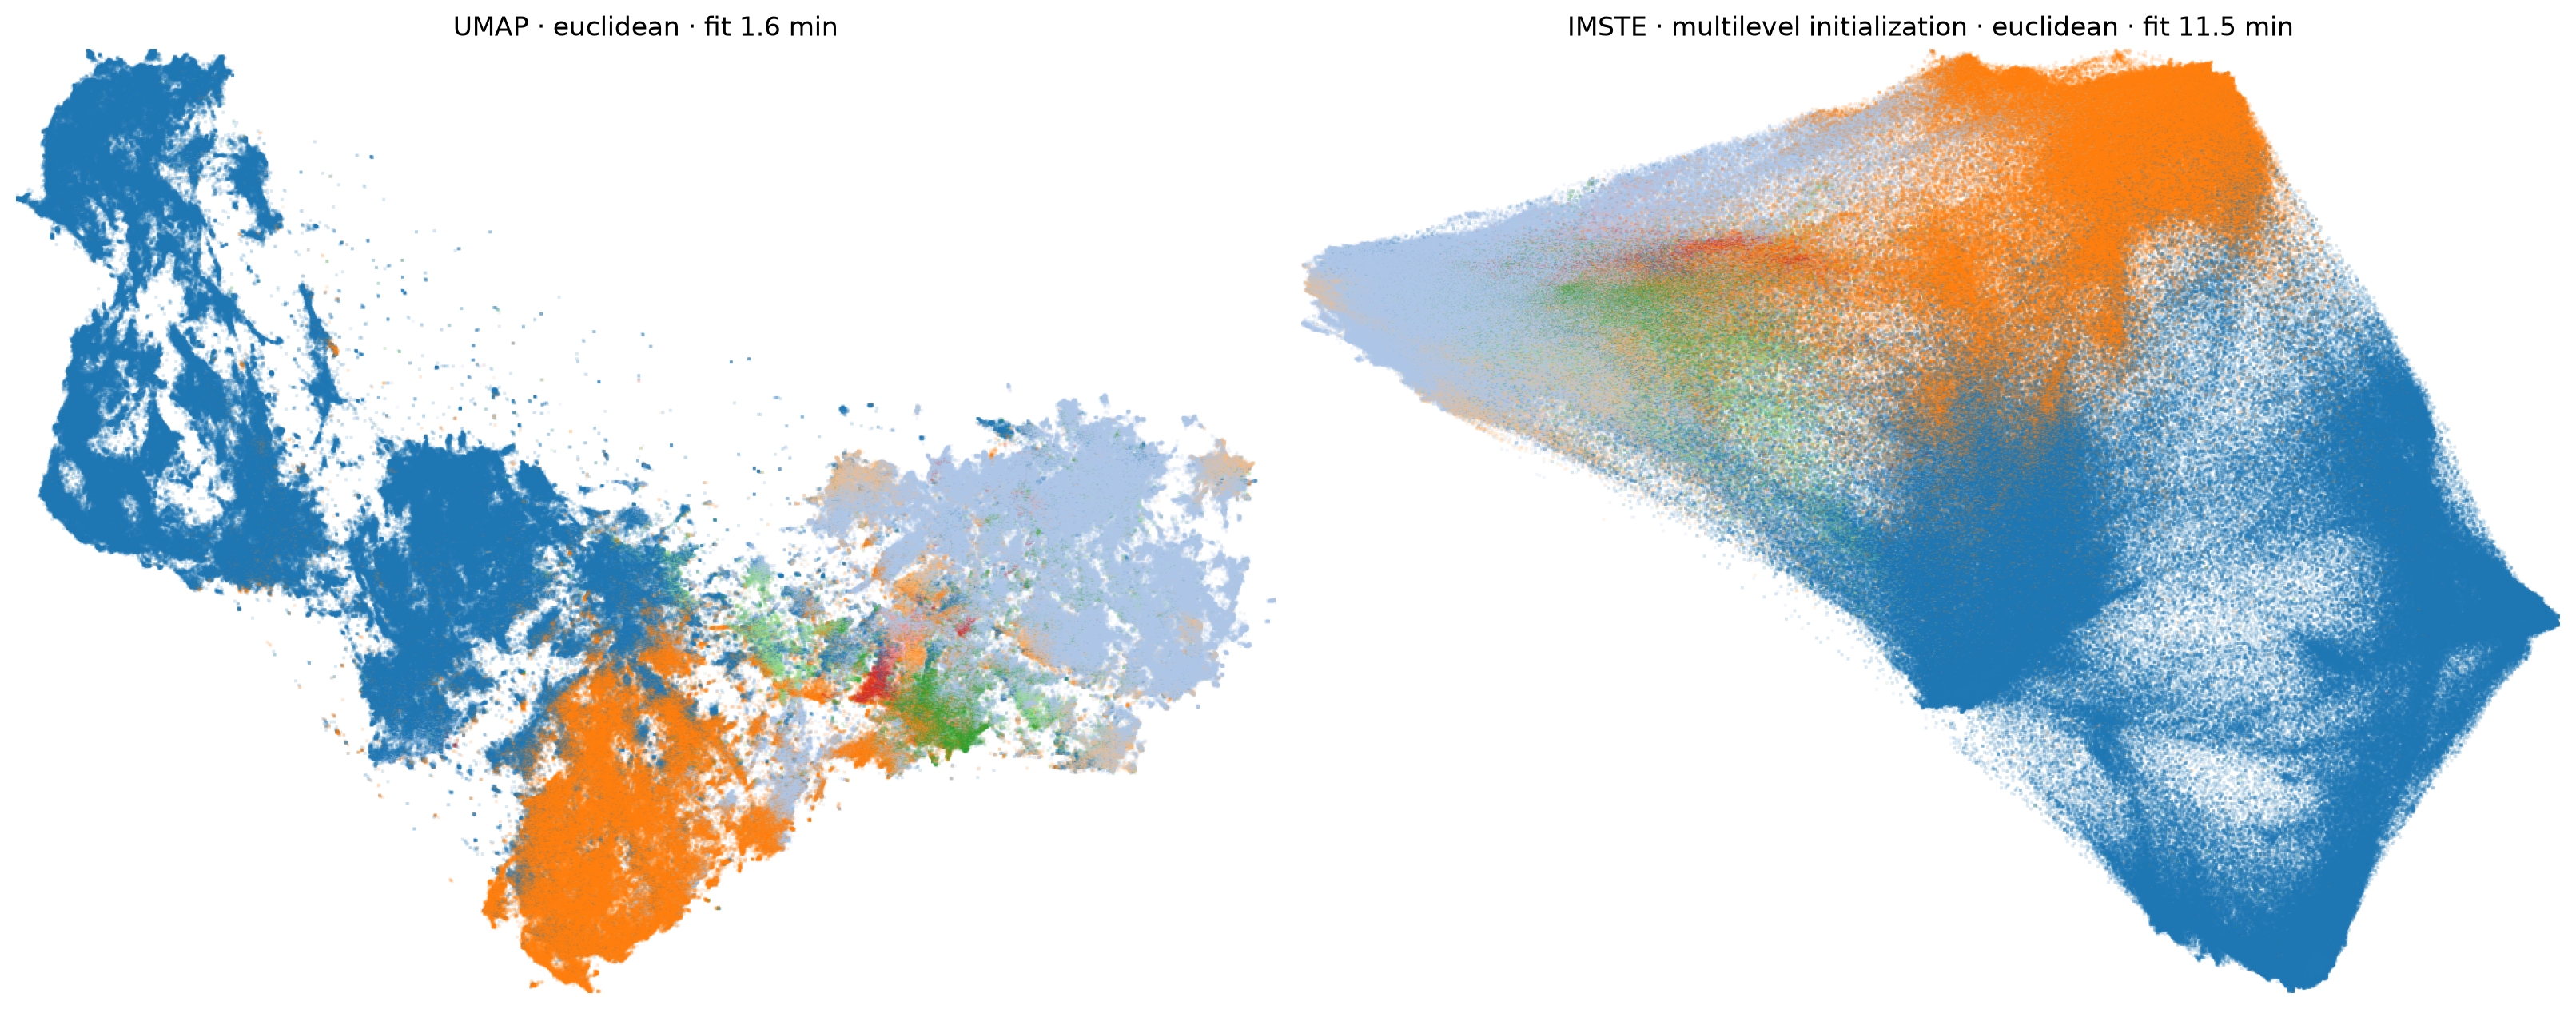

In [7]:
import matplotlib.pyplot as plt
from matplotlib.colors import to_hex
from IPython.display import display
from imste.visualization import render_datashader_embedding

domain_order = list(labels.categories)
palette = plt.get_cmap("tab20")
domain_color_key = {
    domain: to_hex(palette(index % palette.N))
    for index, domain in enumerate(domain_order)
}
label_values = labels.astype(str)

fig, axes = plt.subplots(1, 2, figsize=(16, 7), constrained_layout=True)
for ax, method, coordinates, seconds in zip(
    axes, ("UMAP", "IMSTE · multilevel initialization"),
    (Z_umap, Z_imste), (umap_seconds, imste_seconds),
):
    image = render_datashader_embedding(
        coordinates[:, :2], label_values, width=1200, height=900,
        color_key=domain_color_key, min_alpha=40, background="white",
        spread_px=1,
    )
    ax.imshow(image.to_pil())
    runtime = f"{seconds / 60:.1f} min" if seconds >= 60 else f"{seconds:.1f} s"
    ax.set_title(f"{method} · {METRIC} · fit {runtime}")
    ax.set_axis_off()
display(fig)
plt.close(fig)
